# Large context with SAP-RPT-1.6-large and `context_mode="deep"`

RPT learns *in context*: every request carries labeled example rows, and the model predicts the `[PREDICT]` cells from them. More relevant context usually means better answers, but each model has a context limit:

| Model | Max context rows | Recommended |
|---|---|---|
| `sap-rpt-1.6` | 2,048 | 500-2,000 |
| `sap-rpt-1.6-large` | 65,536 | 4,000-36,000 |

`sap-rpt-1.6-large` also accepts `prediction_config.context_mode`:

* `"default"`: best balance of accuracy and latency.
* `"deep"`: trades latency for accuracy. SAP recommends it **only with `sap-rpt-1.6-large` and more than 8,000 context rows**, after trying `sap-rpt-1.6` and then `sap-rpt-1.6-large` in default mode.

This notebook follows that recommendation on a real dataset and measures whether more context and deep mode pay off:

1. `sap-rpt-1.6` with a 2,048-row random sample of the context (its maximum).
2. `sap-rpt-1.6-large` with the full context (~16,000 rows), `default` mode.
3. `sap-rpt-1.6-large` with the full context, `deep` mode.

**Data:** `data/OVERNIGHTSTAYS.csv`, public Swiss hotel statistics (Federal Statistical Office, dataset px-x-1003020000_103): monthly overnight stays per tourism region and guests' country of residence, January 2022 to May 2024.

## 1. Setup

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import find_dotenv, load_dotenv
from tqdm.auto import tqdm

from rpt_client_api import RPTClientAPI

_ = load_dotenv(find_dotenv(usecwd=True))

## 2. Load the data

`MONTH` is stored as `DD/MM/YYYY`. RPT expects ISO dates (`YYYY-MM-DD`), so dates are parsed explicitly here instead of relying on server-side normalization.

In [2]:
stays = pd.read_csv("data/OVERNIGHTSTAYS.csv", encoding="utf-8-sig")
stays["MONTH"] = pd.to_datetime(stays["MONTH"], format="%d/%m/%Y")
print(stays.shape, "| months:", stays["MONTH"].nunique(),
      "| regions:", stays["REGION"].nunique(), "| countries:", stays["COUNTRYOFRESIDENCE"].nunique())
stays["OVERNIGHTSTAYS"].describe().round(0)

(29029, 4) | months: 29 | regions: 13 | countries: 77


count     29029.0
mean       3307.0
std       19416.0
min           0.0
25%          58.0
50%         269.0
75%        1066.0
max      583762.0
Name: OVERNIGHTSTAYS, dtype: float64

## 3. Shape the table for RPT

RPT predicts a cell from the *other columns of the same row*; it does not read rows as a time series. Two preparation steps matter here:

* **Lag features.** Add the previous month and the same month one year earlier as columns, so each row carries its own history. Rows of the first year have no 12-month lag and are dropped.
* **Log scale for a heavy-tailed target.** Stays range from 0 to over 580,000 (median ~270). We predict `log1p(stays)` and transform back with `expm1`. In a first trial on raw counts the model lost to the naive baseline; on log scale it beat it.

`MONTH_OF_YEAR` (as text) gives the model the season without exposing the absolute date.

In [3]:
SERIES_KEY = ["REGION", "COUNTRYOFRESIDENCE"]
table = stays.sort_values([*SERIES_KEY, "MONTH"]).copy()
table["LOG_STAYS"] = np.log1p(table["OVERNIGHTSTAYS"])
by_series = table.groupby(SERIES_KEY)["LOG_STAYS"]
table["LOG_STAYS_PREVIOUS_MONTH"] = by_series.shift(1)
table["LOG_STAYS_LAST_YEAR"] = by_series.shift(12)
table = table.dropna(subset=["LOG_STAYS_PREVIOUS_MONTH", "LOG_STAYS_LAST_YEAR"]).copy()
table["MONTH_OF_YEAR"] = table["MONTH"].dt.month.astype(str)
table["ROW_ID"] = [f"r{i}" for i in range(len(table))]

FEATURES = ["MONTH_OF_YEAR", "REGION", "COUNTRYOFRESIDENCE", "LOG_STAYS_PREVIOUS_MONTH", "LOG_STAYS_LAST_YEAR"]
TARGET = "LOG_STAYS"
table[["ROW_ID", *FEATURES, TARGET]].head()

,ROW_ID,MONTH_OF_YEAR,REGION,COUNTRYOFRESIDENCE,LOG_STAYS_PREVIOUS_MONTH,LOG_STAYS_LAST_YEAR,LOG_STAYS
12969,r0,1,Aargau and Solothurn Region,Argentina,3.433987,0.693147,0.000000
13970,r1,2,Aargau and Solothurn Region,Argentina,0.000000,1.609438,2.079442
14971,r2,3,Aargau and Solothurn Region,Argentina,2.079442,0.693147,3.970292
15972,r3,4,Aargau and Solothurn Region,Argentina,3.970292,3.135494,4.158883
16973,r4,5,Aargau and Solothurn Region,Argentina,4.158883,2.708050,4.770685


## 4. Context and query split

* **Query:** the most recent month (one row per region x country). The true values are kept aside for scoring.
* **Context:** all earlier months.

RPT accepts at most 512 query rows per request, so the query month is sent in batches. The guard makes sure deep mode is only used where SAP recommends it.

In [4]:
last_month = table["MONTH"].max()
context = table[table["MONTH"] < last_month]
query = table[table["MONTH"] == last_month]
print(f"context rows: {len(context):,} | query rows: {len(query):,} | query month: {last_month:%Y-%m}")

DEEP_MODE_MIN_CONTEXT = 8_000
assert len(context) > DEEP_MODE_MIN_CONTEXT, "deep mode is only recommended above 8,000 context rows"

context rows: 16,016 | query rows: 1,001 | query month: 2024-05


## 5. Prediction helper

`predict_in_batches` sends the full context with each batch of up to 512 query rows and returns the predictions on the original scale. Bodies are gzip-compressed (`compress=True`) because 16,000 rows are a few MB of JSON. The client timeout is raised for deep mode.

In [5]:
COLUMNS = ["ROW_ID", *FEATURES, TARGET]
MAX_QUERY_ROWS = 512


def predict_in_batches(model_name, context_rows, context_mode="default"):
    '''Predict TARGET for every query row and return (predictions on stays scale, seconds).'''
    client = RPTClientAPI(model_name=model_name, timeout_s=600)
    context_records = context_rows[COLUMNS].to_dict(orient="records")
    predictions, elapsed = {}, 0.0
    batches = range(0, len(query), MAX_QUERY_ROWS)
    for start in tqdm(batches, desc=f"{model_name} / {context_mode}"):
        batch = query.iloc[start:start + MAX_QUERY_ROWS][COLUMNS].copy()
        batch[TARGET] = "[PREDICT]"
        prediction_config = {
            "target_columns": [
                {"name": TARGET, "prediction_placeholder": "[PREDICT]", "task_type": "regression"}
            ]
        }
        if model_name.startswith("sap-rpt-1.6"):
            prediction_config["context_mode"] = context_mode
        payload = {
            "index_column": "ROW_ID",
            "prediction_config": prediction_config,
            "rows": context_records + batch.to_dict(orient="records"),
        }
        started = time.perf_counter()
        response = client.predict_json(payload, compress=True)
        elapsed += time.perf_counter() - started
        for record in response["predictions"]:
            predictions[record["ROW_ID"]] = float(record[TARGET][0]["prediction"])
    log_predictions = pd.Series(predictions).reindex(query["ROW_ID"]).to_numpy()
    return np.expm1(log_predictions), elapsed

## 6. Run the three setups

The naive baseline repeats the value of the same month last year, a common seasonal benchmark; any model worth using should beat it.

In [6]:
setups = {
    "sap-rpt-1.6, 2,048 sampled rows": ("sap-rpt-1.6", context.sample(2_048, random_state=0), "default"),
    "sap-rpt-1.6-large, full, default": ("sap-rpt-1.6-large", context, "default"),
    "sap-rpt-1.6-large, full, deep": ("sap-rpt-1.6-large", context, "deep"),
}
actual = query["OVERNIGHTSTAYS"].to_numpy()
results = {"naive: same month last year": (np.expm1(query["LOG_STAYS_LAST_YEAR"].to_numpy()), 0.0, 0)}
for name, (model_name, context_rows, mode) in setups.items():
    predicted, seconds = predict_in_batches(model_name, context_rows, mode)
    results[name] = (predicted, seconds, len(context_rows))

sap-rpt-1.6 / default:   0%|          | 0/2 [00:00<?, ?it/s]

sap-rpt-1.6-large / default:   0%|          | 0/2 [00:00<?, ?it/s]

sap-rpt-1.6-large / deep:   0%|          | 0/2 [00:00<?, ?it/s]

## 7. Compare

* **MAE**: mean absolute error in stays. Large regions dominate it.
* **Median AE**: typical error of a single row.
* **Log MAE**: mean absolute error of `log1p` values; roughly the typical *relative* error, robust to scale.

In [7]:
def scores(predicted):
    '''Return error metrics of predicted stays against the held-out month.'''
    error = predicted - actual
    return {
        "MAE": np.abs(error).mean(),
        "median AE": np.median(np.abs(error)),
        "log MAE": np.abs(np.log1p(np.clip(predicted, 0, None)) - np.log1p(actual)).mean(),
    }


summary = pd.DataFrame(
    {name: {**scores(pred), "context rows": rows, "total latency (s)": secs}
     for name, (pred, secs, rows) in results.items()}
).T
summary.round(3)

,MAE,median AE,log MAE,context rows,total latency (s)
naive: same month last year,357.282,72.000,0.378,0.0,0.000
"sap-rpt-1.6, 2,048 sampled rows",360.649,67.094,0.315,2048.0,1.340
"sap-rpt-1.6-large, full, default",331.155,56.679,0.306,16016.0,2.978
"sap-rpt-1.6-large, full, deep",325.109,59.892,0.310,16016.0,4.837


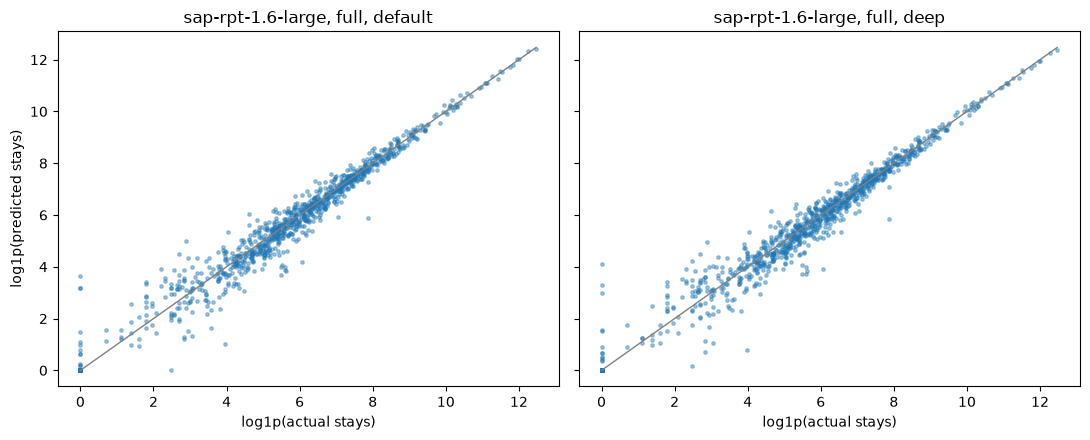

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for axis, name in zip(axes, ["sap-rpt-1.6-large, full, default", "sap-rpt-1.6-large, full, deep"]):
    axis.scatter(np.log1p(actual), np.log1p(np.clip(results[name][0], 0, None)), s=6, alpha=0.4)
    limit = np.log1p(actual.max())
    axis.plot([0, limit], [0, limit], color="grey", linewidth=1)
    axis.set_title(name)
    axis.set_xlabel("log1p(actual stays)")
axes[0].set_ylabel("log1p(predicted stays)")
plt.tight_layout()

## Takeaways

* **Prepare the table.** On a heavy-tailed target, predicting the log value and adding lag columns decided whether RPT beat a naive benchmark at all.
* **More context helped.** Moving from 2,048 sampled rows on `sap-rpt-1.6` to the full ~16,000 rows on `sap-rpt-1.6-large` reduced the errors in our run.
* **Deep mode is not automatically better.** On this dataset `deep` gave about the same accuracy as `default` at higher latency. Follow SAP's sequence (1.6, then 1.6-large default, then deep) and keep deep only if it measurably wins on your own holdout.
* **Request mechanics.** Up to 512 query rows per call, gzip for large bodies, and a longer client timeout for deep mode.